# Guía práctica 4

## Ejercicio 4 - Análisis armónico

Dos tonos: $A_1 = 1$ en $f_1$ y $A_2 = 0.01$ en $f_2 = 16 f_s/N$. El tono chico
está $20\log_{10}(0.01) = -40$ dB por debajo del grande.

In [9]:
from matplotlib.pyplot import show, subplots, tight_layout
from numpy import (
    abs,
    arange,
    bartlett,
    blackman,
    hamming,
    kaiser,
    log10,
    maximum,
    ones,
    pi,
    sin,
)
from numpy.fft import fft

In [10]:
sampling_freq_hz = 1000
n_samples = 1024
freq_resolution_hz = sampling_freq_hz / n_samples

n_fft = 65536
oversampling = n_fft // n_samples

w_rect = ones(n_samples)
W_db = 20 * log10(maximum(abs(fft(w_rect, n_fft)), 1e-12) / n_samples)

### Incisos a), b) y c): ventana rectangular

La señal son los dos tonos juntos. $f_2$ queda fijo en el bin 16 y lo único que
cambia entre los tres casos es dónde cae $f_1$.

In [11]:
AMPLITUDE_1 = 1.0
AMPLITUDE_2 = 0.01
FREQ_2_BINS = 16

t = arange(n_samples) / sampling_freq_hz


def two_tones(freq_1_bins):
    freq_1_hz = freq_1_bins * freq_resolution_hz
    freq_2_hz = FREQ_2_BINS * freq_resolution_hz
    return AMPLITUDE_1 * sin(2 * pi * freq_1_hz * t) + AMPLITUDE_2 * sin(
        2 * pi * freq_2_hz * t
    )


def spectrum_db(x, w):
    # Normalised to the peak, so the big tone sits at 0 dB and the small one
    # should sit at -40 dB.
    X = abs(fft(x * w))
    return 20 * log10(maximum(X, 1e-12) / X.max())

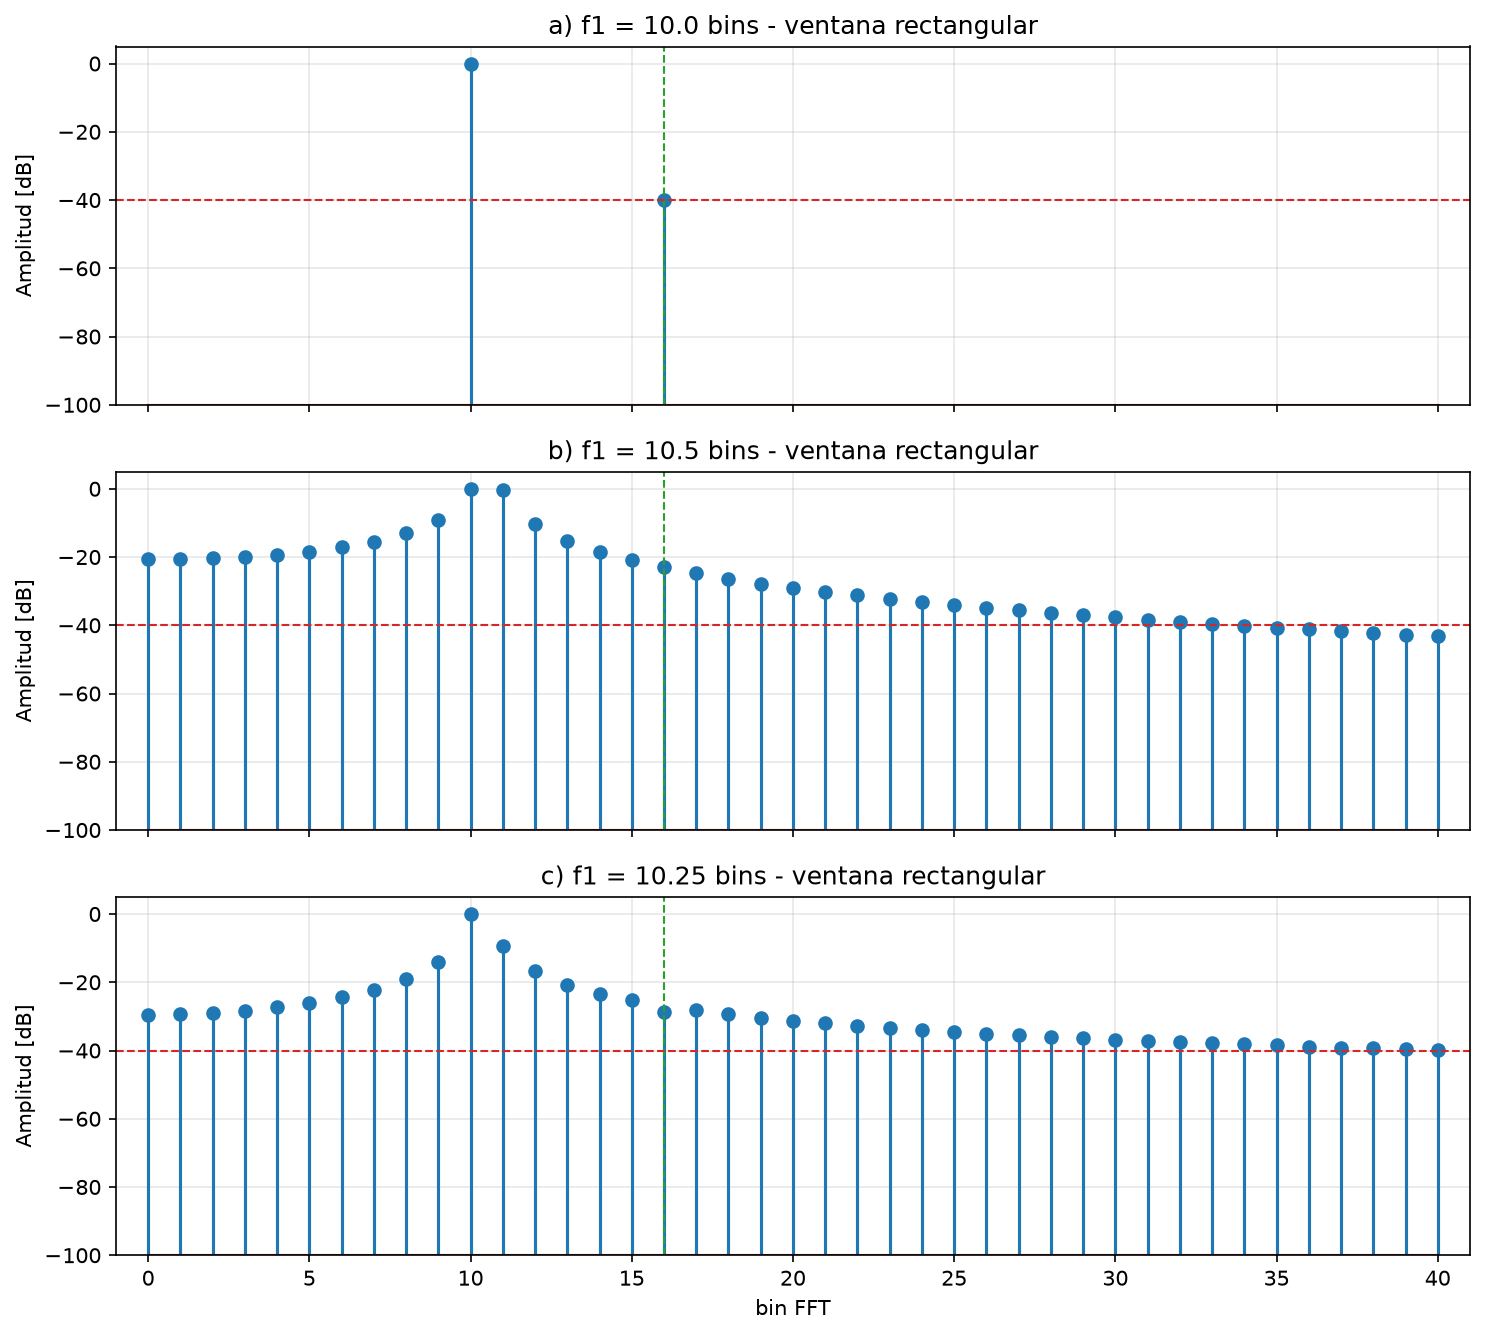

In [17]:
cases = [("a", 10.0), ("b", 10.5), ("c", 10.25)]
k = arange(41)

fig, axes = subplots(len(cases), 1, figsize=(10, 9), dpi=150, sharex=True, sharey=True)

for ax, (name, freq_1_bins) in zip(axes, cases):
    ax.stem(
        k,
        spectrum_db(two_tones(freq_1_bins), w_rect)[k],
        bottom=-100,
    )
    ax.axvline(FREQ_2_BINS, color="C2", linestyle="--", linewidth=1.0)
    ax.axhline(-40, color="C3", linestyle="--", linewidth=1.0)
    ax.set_title(f"{name}) f1 = {freq_1_bins} bins - ventana rectangular")
    ax.set_ylabel("Amplitud [dB]")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("bin FFT")
axes[-1].set_xlim(-1, 41)
axes[-1].set_ylim(-100, 5)
tight_layout()
show()

In [18]:
print(f"{'caso':>6} {'f1 [bins]':>10} {'nivel en bin 16':>17}")
for name, freq_1_bins in cases:
    level_db = spectrum_db(two_tones(freq_1_bins), w_rect)[FREQ_2_BINS]
    print(f"{name:>6} {freq_1_bins:>10.2f} {level_db:>14.2f} dB")

  caso  f1 [bins]   nivel en bin 16
     a      10.00         -40.00 dB
     b      10.50         -22.85 dB
     c      10.25         -28.77 dB


La línea verde marca el bin 16, donde está el tono chico. La roja, los $-40$ dB
que debería medir.

En **a)** el pico del bin 16 llega justo a $-40$ dB. En **b)** y **c)** el bin 16
mide bastante más que $-40$ dB, y además no se distingue como un pico, es la
falda del tono grande pasando por ahí. El tono chico está tapado.

### Incisos d), e), f) y g): otras ventanas

Todas se aplican al caso peor, $f_1 = 10.5$ bins (justo entre dos bines). El valor de $\beta$ para
Kaiser sale de la tabla de `numpy.kaiser`, que da $\beta = 8.6$ como equivalente
a Blackman.

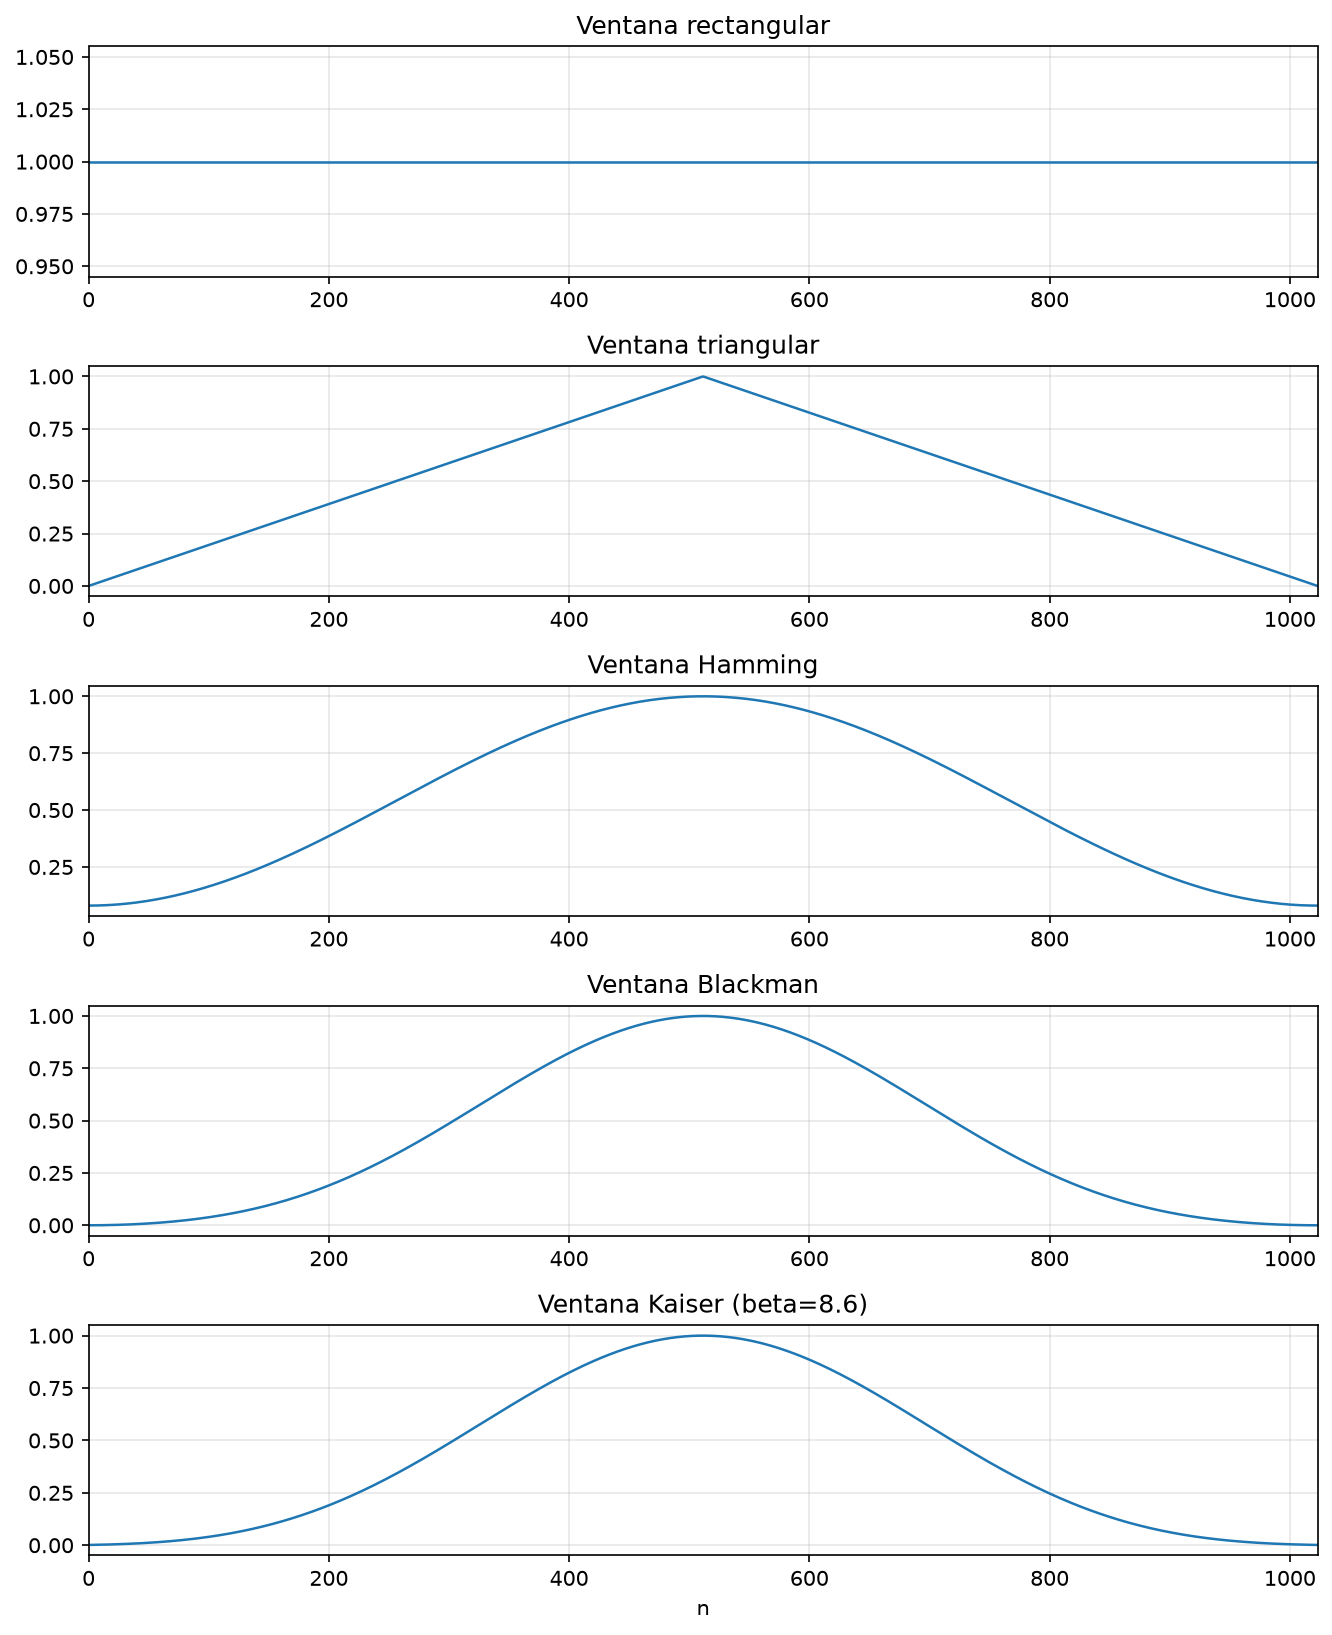

In [19]:
KAISER_BETA = 8.6

windows = [
    ("rectangular", w_rect),
    ("triangular", bartlett(n_samples)),
    ("Hamming", hamming(n_samples)),
    ("Blackman", blackman(n_samples)),
    (f"Kaiser (beta={KAISER_BETA})", kaiser(n_samples, KAISER_BETA)),
]

fig, axes = subplots(len(windows), 1, figsize=(9, 3), dpi=150)
fig.set_figheight(2.2 * len(windows))

for ax, (name, w) in zip(axes, windows):
    ax.plot(arange(n_samples), w, "C0-", linewidth=1.2)
    ax.set_title(f"Ventana {name}")
    ax.set_xlim(0, n_samples - 1)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("n")
tight_layout()
show()

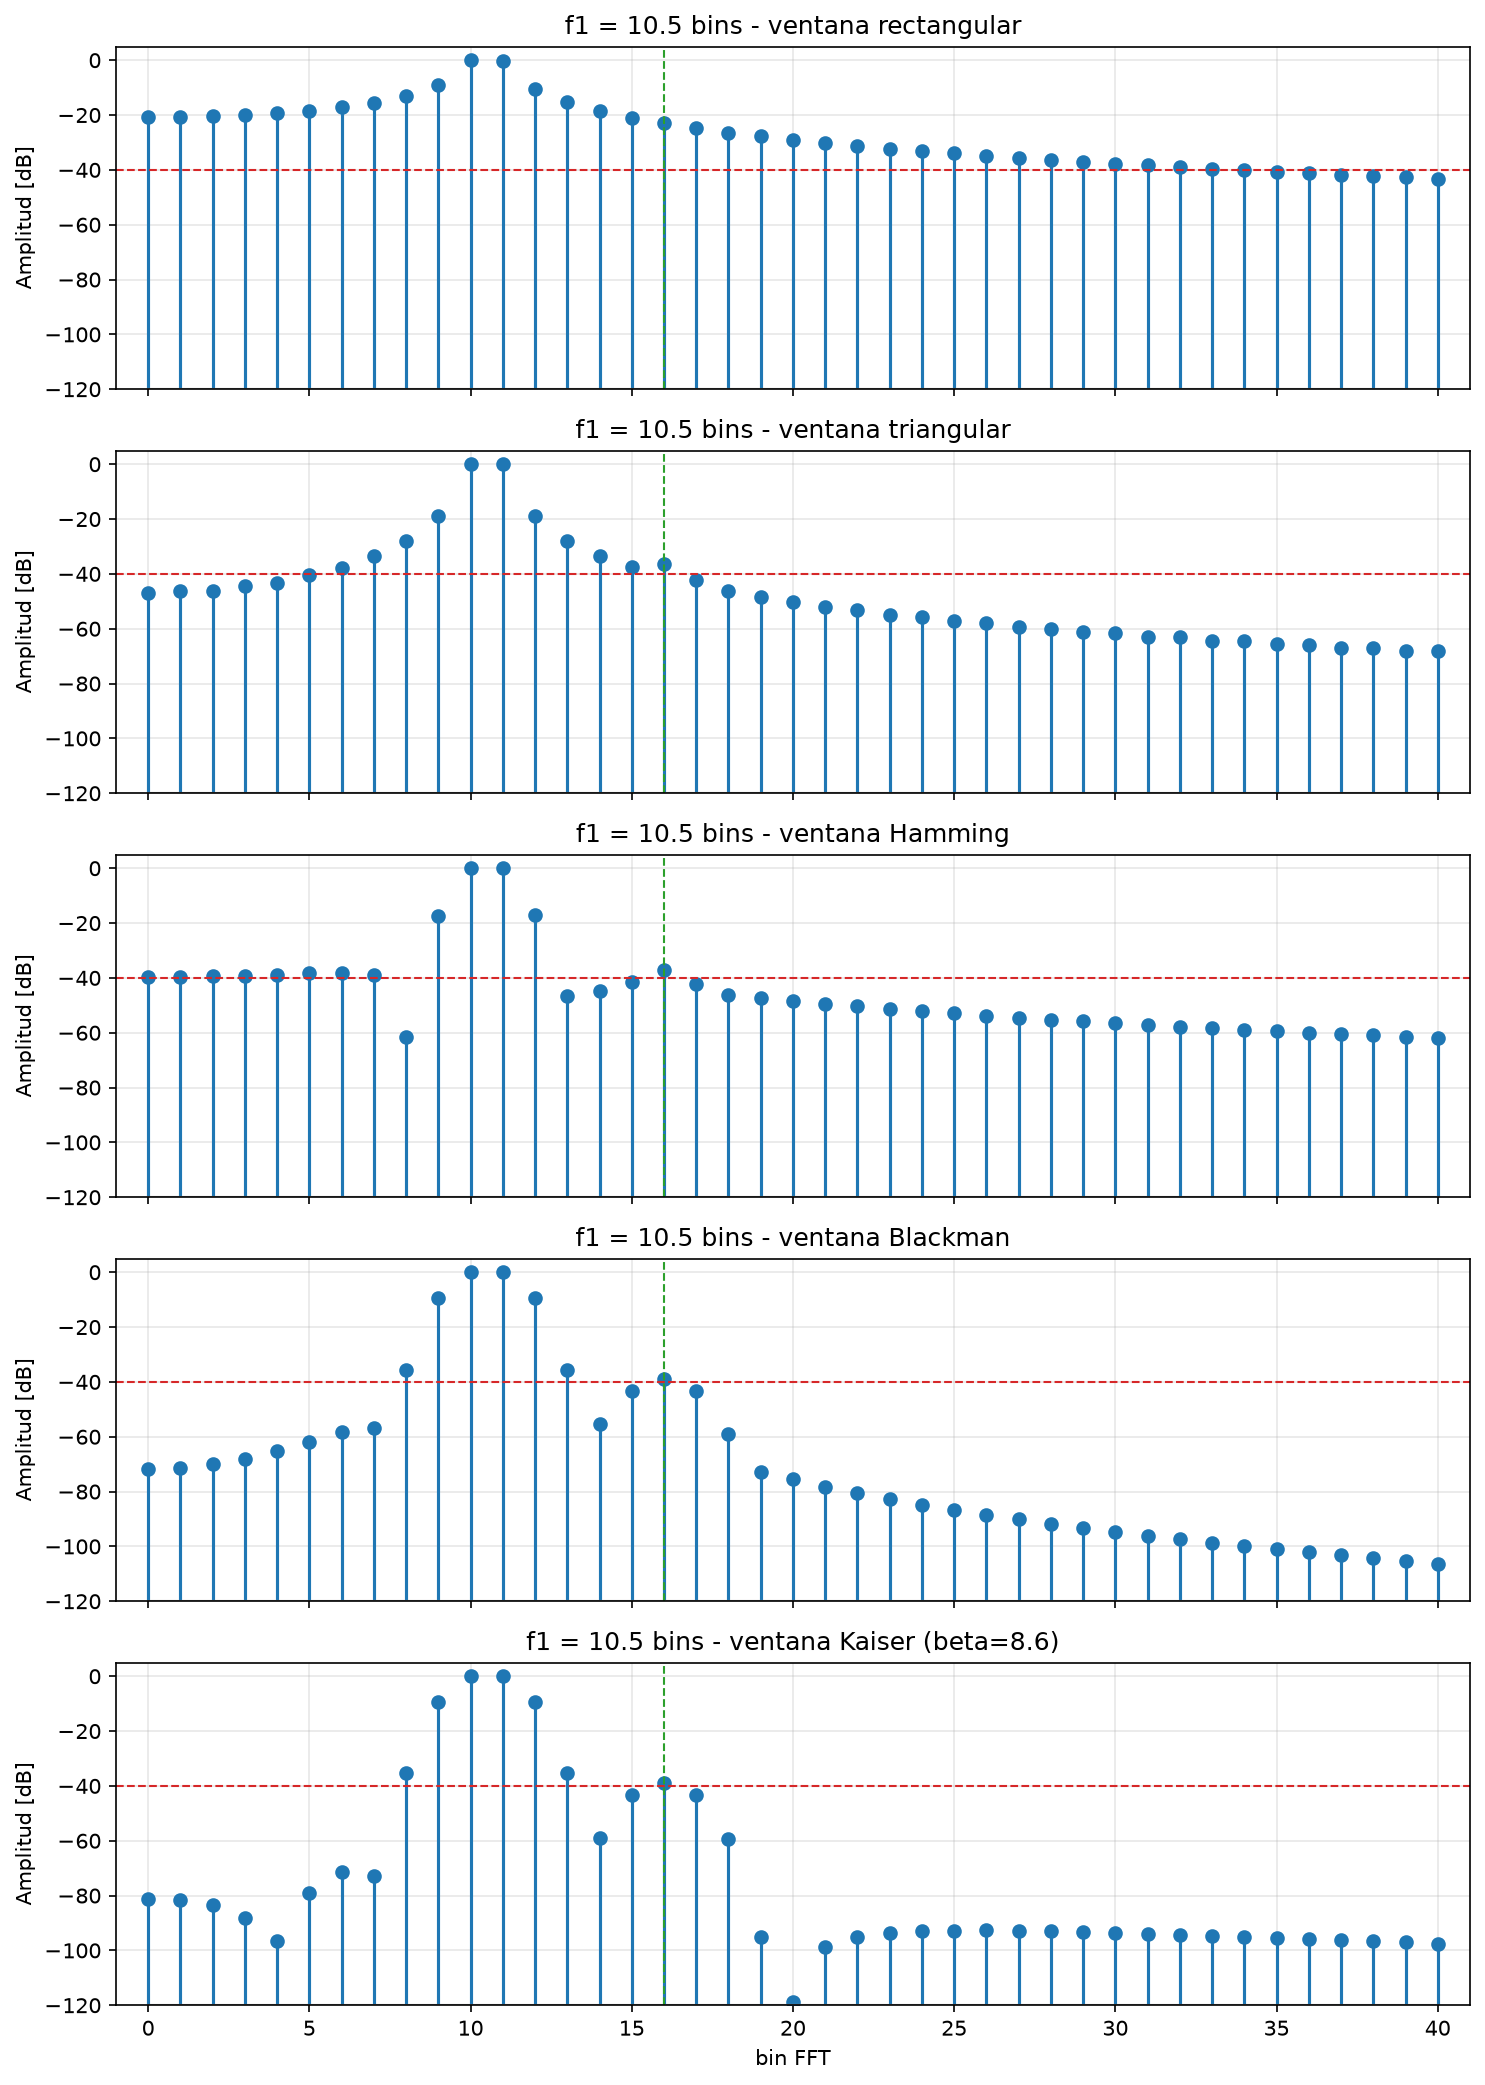

In [20]:
FREQ_1_BINS_WORST = 10.5
k = arange(41)

fig, axes = subplots(
    len(windows), 1, figsize=(10, 14), dpi=150, sharex=True, sharey=True
)

for ax, (name, w) in zip(axes, windows):
    ax.stem(
        k,
        spectrum_db(two_tones(FREQ_1_BINS_WORST), w)[k],
        linefmt="C0-",
        markerfmt="C0o",
        basefmt="#999999",
        bottom=-120,
    )
    ax.axvline(FREQ_2_BINS, color="C2", linestyle="--", linewidth=1.0)
    ax.axhline(-40, color="C3", linestyle="--", linewidth=1.0)
    ax.set_title(f"f1 = {FREQ_1_BINS_WORST} bins - ventana {name}")
    ax.set_ylabel("Amplitud [dB]")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("bin FFT")
axes[-1].set_xlim(-1, 41)
axes[-1].set_ylim(-120, 5)
tight_layout()
show()

In [21]:
def window_figures(w):
    W = abs(fft(w, n_fft))
    W_db = 20 * log10(maximum(W, 1e-12) / W.max())

    # Walk out from the peak until the curve stops decreasing: that is the
    # first null, and everything beyond it is sidelobe.
    i = 1
    while W_db[i] < W_db[i - 1]:
        i += 1
    return i / oversampling, W_db[i : n_fft // 2].max()


print(f"{'ventana':>20} {'1er nulo':>10} {'lob. lat.':>11} {'bin 16':>10} {'pico?':>7}")
for name, w in windows:
    first_null_bins, max_sidelobe_db = window_figures(w)
    spectrum = spectrum_db(two_tones(FREQ_1_BINS_WORST), w)
    is_peak = spectrum[FREQ_2_BINS] > max(
        spectrum[FREQ_2_BINS - 1], spectrum[FREQ_2_BINS + 1]
    )
    print(
        f"{name:>20} {first_null_bins:>7.2f} b {max_sidelobe_db:>8.1f} dB "
        f"{spectrum[FREQ_2_BINS]:>7.1f} dB {is_peak!s:>7}"
    )

             ventana   1er nulo   lob. lat.     bin 16   pico?
         rectangular    1.02 b    -13.3 dB   -22.9 dB   False
          triangular    2.02 b    -26.5 dB   -36.5 dB    True
             Hamming    2.02 b    -42.7 dB   -37.3 dB    True
            Blackman    3.02 b    -58.1 dB   -38.9 dB    True
   Kaiser (beta=8.6)    2.94 b    -63.2 dB   -38.9 dB    True


### Conclusiones

La ventana rectangular es la peor para este problema. Con $f_1$ fuera de
bin, su fuga a 5.5 bins vale $-23$ dB, muy por encima del tono de $-40$ dB. El
bin 16 ni siquiera es un máximo local. Cualquier ventana con lóbulos laterales más bajos resuelve el problema. Ya la triangular hace aparecer el pico, aunque con 3.5 dB de error. Hamming, Blackman y Kaiser lo miden con menos de 1.1 dB de error.

En estos casos el precio a pagar es la resolución. El lóbulo principal pasa de 1 bin
(rectangular) a 2 (triangular, Hamming) y a 3 (Blackman, Kaiser). Dos tonos
separados por menos que ese ancho dejan de distinguirse. Acá no molesta porque
los tonos están a 5.5 bins, pero si estuvieran a 2 bins, Blackman los fusionaría, por ejemplo.

Se debe manejar un compromiso entre la resolución y el rango dinámico requerido. Bajar los lóbulos laterales para hacer más evidentes frecuencias cercanas a su vez implica un ensanchamiento del lóbulo principal en cada frecuencia. 